# Does a change in management's tone help the LLM?

Every call summary has a **TONE AND CAUTION** section: management's cautious or confident language, quoted briefly.
The prompt variant `tone_change` adds the same section from the company's **earlier calls** (up to 3, most recent
first) and asks the model to judge how the tone changed: more confident than before is usually good news, more
cautious usually bad news. Everything else is the same as the base run: same model, same summaries, temperature 0.

**Setup**
- **Calls:** every 2025 in-sample call with an earlier summarized call of the same company 45 to 400 days before
  (so the earlier call was public well before this one). Calls from Q1 2025 have no earlier call in the data, so
  the test is in practice Q2 to Q4 2025, with 1, 2 or 3 earlier calls in the prompt.
- **Runs:** the base prompt (already scored) against `tone_change`, on the same calls.
- **Measure:** day-0 R², as in `llm_eval`: how much of the ranking of the event-day abnormal return the score
  explains. Higher is better.

**Answer: no, keep the base prompt.** The tone history carries a small real signal, but as part of the prompt it
makes the LLM score worse.
- **Worse on its own:** with the earlier tone notes in the prompt, the LLM score explains 6.79% of day-0 returns
  against 7.70% with the base prompt: -0.91 pp (95% interval -1.44 to -0.37 pp). Together with the surprise it is
  12.28% against 12.69%, -0.41 pp (-0.83 to +0.02 pp). It is lower in every quarter, so more history (Q4 calls see
  3 earlier calls) doesn't fix it.
- **The prompt made the model gloomier:** it lowered 52% of the scores and raised only 4% (mean change -0.06).
  The tone notes are mostly cautious quotes by design (the summary section is called TONE AND CAUTION), so lining
  up a year of them reads as extra bad news even when nothing changed.
- **A small real signal:** the few calls whose score it raised (285, 4%) did better than the surprise and the base
  score predict, by about 4 percentile points of the return ranking (95% interval +0.9 to +6.9). The tone score
  also adds information beyond the base score (p = 0.009). But the gain is tiny: +0.08 pp of R² when both scores
  are used together (12.69% to 12.77%), and the plain average of the two scores changes the R² by +0.05 pp (-0.16
  to +0.26 pp), which is noise.

The numbers in this text are from the run of 2026-11-16 (7,416 calls); the cells below recompute them from the
files.

**To rerun**
```bash
NSHARDS=4 VARIANT=tone_change sbatch --array=0-3 --time=02:00:00 run_llm.sh
uv run python -m llm_based_earnings_surprise_ntam.llm.llm_combine     # after the jobs
```
Sections 2 to 5 are skipped until the calls are scored with `tone_change`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import statsmodels.formula.api as smf

from llm_based_earnings_surprise_ntam.llm.llm_common import MERGED, MODEL, SCORES, SUMMARIES, load_all, with_run_defaults
from llm_based_earnings_surprise_ntam.llm.llm_tone import tone_history

pd.set_option('display.width', 200)

# Same chart style as the other notebooks; categorical colors in fixed order (base = blue, tone = orange)
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, INK2, SURFACE = '#0b0b0b', '#52514e', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK2, 'text.color': INK,
    'xtick.color': INK2, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e8e7e3', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.figsize': (10, 4), 'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})
pct0 = mtick.PercentFormatter(1, decimals=0)
pp = mtick.FuncFormatter(lambda v, _: f'{v * 100:+.1f} pp')

## 1. The calls and the scores

The earlier calls' tone notes are rebuilt here from the summaries with the same function the scoring job used
(`llm_tone.tone_history`), so the calls below are exactly the ones that were scored.

In [2]:
VARIANT = 'tone_change'
SCORES_FILE = SCORES

calls = pd.read_parquet(MERGED, columns=['transcriptid', 'companyid', 'call_date', 'in_sample', 'r_abn_pct',
                                         'sue_pct_sample'])
calls['transcriptid'] = calls.transcriptid.astype('int64')
hist = tone_history(calls, load_all(SUMMARIES))
ins = calls[calls.in_sample.fillna(False).astype(bool)]
m = ins.merge(hist, on='transcriptid').set_index('transcriptid')

s = with_run_defaults(load_all(SCORES_FILE))
s['transcriptid'] = s.transcriptid.astype('int64')
s = s[s.model.eq(MODEL) & s.source.eq('summary') & s.temperature.eq(0) & s.samples.eq(1)]
def run_of(variant):
    g = s[s.variant.eq(variant)].drop_duplicates('transcriptid', keep='last').set_index('transcriptid')
    return g.prediction.astype(float), g.reasons

base, base_reasons = run_of('base')
tone, tone_reasons = run_of(VARIANT)
m['llm_base'], m['llm_tone'] = base, tone
m['quarter'] = 'Q' + m.call_date.dt.quarter.astype(str)
n_elig, n_scored = len(m), int(m.llm_tone.notna().sum())
HAVE_VARIANT = n_scored >= 0.99 * n_elig          # a handful of failed answers is fine
m = m.dropna(subset=['r_abn_pct', 'sue_pct_sample', 'llm_base'] + (['llm_tone'] if HAVE_VARIANT else []))

q = ins.call_date.dt.quarter.map(lambda k: f'Q{k}')
cover = pd.DataFrame({'in-sample calls': q.value_counts(),
                      'with an earlier call': m.quarter.value_counts()}).fillna(0).astype(int).sort_index()
cover['share'] = (cover['with an earlier call'] / cover['in-sample calls']).map('{:.0%}'.format)
for k in (1, 2, 3):
    cover[f'{k} earlier call{"s" if k > 1 else ""} in the prompt'] = m[m.n_prev.eq(k)].quarter.value_counts()
cover = cover.fillna(0).astype({c: int for c in cover.columns if c != 'share'})
cover.loc['all'] = [cover[c].sum() if c != 'share' else f"{len(m) / len(ins):.0%}" for c in cover.columns]
print(f'{n_elig:,} in-sample calls have an earlier call; {n_scored:,} of them are scored with {VARIANT}.')
print(f"Tone notes in the prompt: a median of {m.tone_history.str.split().str.len().median():.0f} words; "
      f"the most recent earlier call is a median of {m.prev_days.median():.0f} days before.")
cover

7,416 in-sample calls have an earlier call; 7,416 of them are scored with tone_change.
Tone notes in the prompt: a median of 65 words; the most recent earlier call is a median of 91 days before.


,in-sample calls,with an earlier call,share,1 earlier call in the prompt,2 earlier calls in the prompt,3 earlier calls in the prompt
Q1,2500,11,0%,11,0,0
Q2,2626,2379,91%,2367,12,0
Q3,2594,2510,97%,254,2249,7
Q4,2584,2516,97%,91,265,2160
all,10304,7416,72%,2723,2526,2167


## 2. Base prompt against tone prompt

Both prompts score the same calls. For each: the R² of the LLM score alone and together with the surprise. The
**change** is tone prompt minus base prompt on the same calls.

The **95% intervals** come from a bootstrap that resamples **companies**, not calls (2,000 times): a company
appears in up to 3 quarters, and its calls are not independent. Every statistic uses the same resamples, so the
change compares the same calls.

Two ways to use both prompts are checked as well: the **average** of the two scores (no weights fitted, so no
advantage from fitting), and the sharper question in the last line: does the tone score carry information the base
score doesn't? That regresses the return on the surprise, the base score and the tone score, and tests that the
tone score's coefficient is zero (standard errors robust to repeated companies). A p-value below 0.05 is a clear
yes; the R² it adds shows whether it is also big enough to matter.

In [3]:
def r2(y, *xs):
    # R² of an OLS regression of y on a constant and xs (as in llm_eval)
    X = np.column_stack([np.ones(len(y)), *xs])
    resid = y - X @ np.linalg.lstsq(X, y, rcond=None)[0]
    return 1 - resid.var() / y.var()

def company_resamples(pos, n=2000, seed=0):
    # bootstrap samples of row positions, drawing whole companies with replacement
    firms = [np.array(v) for v in pd.Series(pos).groupby(m.companyid.to_numpy()[pos]).agg(list)]
    rng = np.random.default_rng(seed)
    return [np.concatenate([firms[j] for j in rng.integers(0, len(firms), len(firms))]) for _ in range(n)]

def p_tone(data):
    # test that the tone score adds nothing beyond the surprise and the base score (company-clustered errors)
    fit = smf.ols('r_abn_pct ~ sue_pct_sample + llm_base + llm_tone', data=data).fit(
        cov_type='cluster', cov_kwds={'groups': data.companyid})
    return float(fit.pvalues['llm_tone']), float(fit.params['llm_tone'])

STATS = ['surprise alone', 'LLM, base prompt', 'LLM, tone prompt', 'surprise + LLM base', 'surprise + LLM tone',
         'LLM, average of the two prompts', 'surprise + LLM average']
def compare(pos):
    y, sue, xb, xt = (m[c].to_numpy()[pos] for c in ('r_abn_pct', 'sue_pct_sample', 'llm_base', 'llm_tone'))
    xa = (xb + xt) / 2
    def stats(i):
        return np.array([r2(y[i], sue[i]), r2(y[i], xb[i]), r2(y[i], xt[i]), r2(y[i], sue[i], xb[i]),
                         r2(y[i], sue[i], xt[i]), r2(y[i], xa[i]), r2(y[i], sue[i], xa[i])])
    local = np.arange(len(pos))
    return stats(local), np.array([stats(np.searchsorted(pos, i)) for i in company_resamples(pos)])

def ci(b):
    return np.percentile(b, 2.5), np.percentile(b, 97.5)

if not HAVE_VARIANT:
    print(f'Skipped: {n_scored:,} of {n_elig:,} calls are scored with {VARIANT} (see the top of the notebook).')
else:
    est, boot = compare(np.arange(len(m)))
    d_alone, d_both = boot[:, 2] - boot[:, 1], boot[:, 4] - boot[:, 3]
    a_alone, a_both = boot[:, 5] - boot[:, 1], boot[:, 6] - boot[:, 3]
    p, coef = p_tone(m)
    r2_three = r2(*(m[c].to_numpy() for c in ('r_abn_pct', 'sue_pct_sample', 'llm_base', 'llm_tone')))
    table = pd.DataFrame({'R²': [f'{v:.2%}' for v in est],
                          '95% interval': [f'{lo:.1%} to {hi:.1%}' for lo, hi in map(ci, boot.T)]}, index=STATS)
    diffs = [(est[2] - est[1], d_alone), (est[4] - est[3], d_both), (est[5] - est[1], a_alone),
             (est[6] - est[3], a_both)]
    change = pd.DataFrame({
        'change against the base prompt': [f'{v * 100:+.2f} pp' for v, _ in diffs],
        '95% interval': [f'{ci(b)[0] * 100:+.2f} to {ci(b)[1] * 100:+.2f} pp' for _, b in diffs],
        'share of resamples where better': [f'{(b > 0).mean():.0%}' for _, b in diffs]},
        index=['tone prompt, score alone', 'tone prompt, with the surprise',
               'average of the two, score alone', 'average of the two, with the surprise'])
    print(f'{len(m):,} calls, {m.companyid.nunique():,} companies')
    display(table)
    display(change)
    print(f'Does the tone score add to the surprise + base score? coefficient {coef:+.3f}, p-value {p:.3f}; '
          f'R² {est[3]:.2%} -> {r2_three:.2%} ({(r2_three - est[3]) * 100:+.2f} pp)')

7,416 calls, 2,713 companies


,R²,95% interval
surprise alone,7.57%,6.3% to 8.9%
"LLM, base prompt",7.70%,6.6% to 8.9%
"LLM, tone prompt",6.79%,5.7% to 8.0%
surprise + LLM base,12.69%,11.2% to 14.2%
surprise + LLM tone,12.28%,10.8% to 13.8%
"LLM, average of the two prompts",7.60%,6.5% to 8.9%
surprise + LLM average,12.73%,11.3% to 14.3%


,change against the base prompt,95% interval,share of resamples where better
"tone prompt, score alone",-0.91 pp,-1.44 to -0.37 pp,0%
"tone prompt, with the surprise",-0.41 pp,-0.83 to +0.02 pp,3%
"average of the two, score alone",-0.09 pp,-0.35 to +0.18 pp,23%
"average of the two, with the surprise",+0.05 pp,-0.16 to +0.26 pp,68%


Does the tone score add to the surprise + base score? coefficient +0.108, p-value 0.009; R² 12.69% -> 12.77% (+0.08 pp)


## 3. By quarter

Q2 calls have one earlier call in the prompt, Q3 calls mostly two and Q4 calls mostly three. If more history
helped, the gain would grow from Q2 to Q4. (Quarter and history length move together here, so this can't separate
the two.)

In [4]:
if HAVE_VARIANT:
    rows = []
    for name, pos in [*[(k, np.flatnonzero(m.quarter.eq(k))) for k in ('Q2', 'Q3', 'Q4')],
                      ('all', np.arange(len(m)))]:
        if name == 'all':
            e, b = est, boot
        else:
            e, b = compare(pos)
        d = b[:, 2] - b[:, 1]
        pq, _ = p_tone(m.iloc[pos])
        rows.append({'calls': len(pos), 'median earlier calls in the prompt': int(m.n_prev.iloc[pos].median()),
                     'surprise alone': e[0], 'LLM base': e[1], 'LLM tone': e[2], 'change': e[2] - e[1],
                     'lo': ci(d)[0], 'hi': ci(d)[1], 'p (tone adds to base + surprise)': pq})
    byq = pd.DataFrame(rows, index=['Q2', 'Q3', 'Q4', 'all'])
    show = byq.copy()
    for c in ('surprise alone', 'LLM base', 'LLM tone'):
        show[c] = show[c].map('{:.2%}'.format)
    show['change (tone - base)'] = [f'{v * 100:+.2f} pp ({lo * 100:+.2f} to {hi * 100:+.2f})'
                                    for v, lo, hi in zip(byq.change, byq.lo, byq.hi)]
    show['p (tone adds to base + surprise)'] = byq['p (tone adds to base + surprise)'].map('{:.3f}'.format)
    display(show.drop(columns=['change', 'lo', 'hi']))

,calls,median earlier calls in the prompt,surprise alone,LLM base,LLM tone,p (tone adds to base + surprise),change (tone - base)
Q2,2379,1,10.28%,7.75%,6.53%,0.223,-1.22 pp (-2.14 to -0.19)
Q3,2510,2,8.01%,8.02%,7.45%,0.016,-0.56 pp (-1.42 to +0.30)
Q4,2516,3,5.10%,7.41%,6.52%,0.190,-0.89 pp (-1.78 to -0.01)
all,7416,2,7.57%,7.70%,6.79%,0.009,-0.91 pp (-1.44 to -0.37)


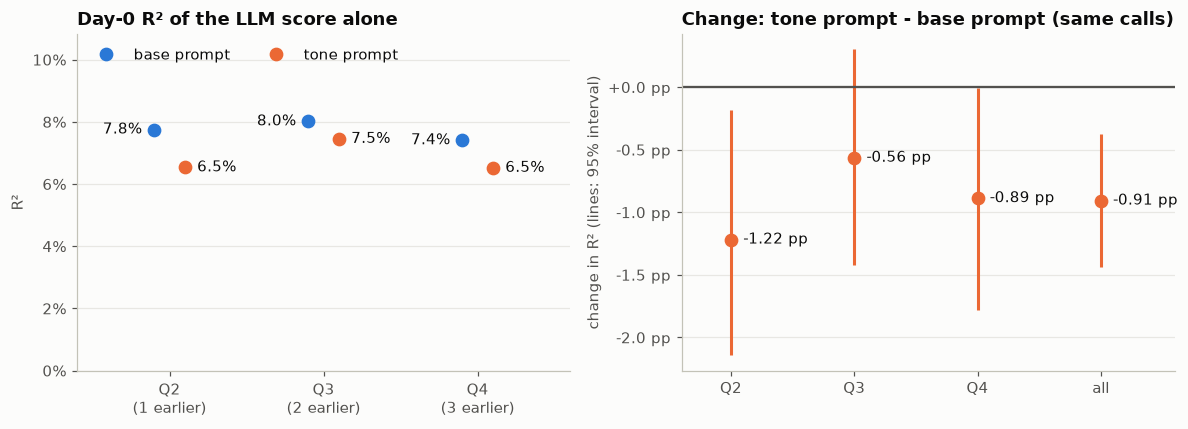

In [5]:
if HAVE_VARIANT:
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
    pos = np.arange(3)
    for k, (col, color, label, dx) in enumerate([('LLM base', BLUE, 'base prompt', -0.1),
                                                 ('LLM tone', ORANGE, 'tone prompt', 0.1)]):
        a1.plot(pos + dx, byq[col].iloc[:3], 'o', color=color, ms=8, label=label)
    for i in pos:
        a1.annotate(f"{byq['LLM tone'].iloc[i]:.1%}", (i + 0.1, byq['LLM tone'].iloc[i]), xytext=(8, 0),
                    textcoords='offset points', va='center', color=INK)
        a1.annotate(f"{byq['LLM base'].iloc[i]:.1%}", (i - 0.1, byq['LLM base'].iloc[i]), xytext=(-8, 0),
                    textcoords='offset points', va='center', ha='right', color=INK)
    a1.set_xticks(pos, [f'{q}\n({n} earlier)' for q, n in zip(byq.index[:3], byq.iloc[:3, 1])])
    a1.set_xlim(-0.6, 2.6)
    a1.set_ylim(0, max(byq[['LLM base', 'LLM tone']].max()) * 1.35)
    a1.set_title('Day-0 R² of the LLM score alone')
    a1.set_ylabel('R²')
    a1.yaxis.set_major_formatter(pct0)
    a1.legend(loc='upper left', ncol=2)

    p2 = np.arange(4)
    a2.errorbar(p2, byq.change, yerr=[byq.change - byq.lo, byq.hi - byq.change], fmt='o', color=ORANGE, ms=8,
                elinewidth=2, capsize=0)
    for i, v in enumerate(byq.change):
        a2.annotate(f'{v * 100:+.2f} pp', (i, v), xytext=(8, 0), textcoords='offset points', va='center', color=INK)
    a2.axhline(0, color=INK2, lw=1.5)
    a2.set_xticks(p2, byq.index)
    a2.set_xlim(-0.4, 3.6)
    a2.set_title('Change: tone prompt - base prompt (same calls)')
    a2.set_ylabel('change in R² (lines: 95% interval)')
    a2.yaxis.set_major_locator(mtick.MaxNLocator(steps=[1, 2, 5, 10]))
    a2.yaxis.set_major_formatter(pp)
    for a in (a1, a2):
        a.grid(axis='x', visible=False)
    fig.tight_layout()
    plt.show()

## 4. How the tone notes moved the scores

If the model used the tone history well, the calls whose score it **raised** should do better on day 0 than the
surprise and the base score predict, and the calls it **lowered** should do worse. The chart shows that
unexplained part: the abnormal-return rank minus what a regression on the surprise and the base score predicts
(0 = as predicted).

The tone prompt changed the score of 56% of calls (raised 4%, lowered 52%); mean change -0.060; correlation with the base score 0.907.
The model's reasons mention tone in 100% of calls with the tone prompt against 78% with the base prompt, and compare with earlier calls in 25% (base: 1%).


,calls,mean,lo,hi,share
group,,,,,
lowered,3872,-0.0069,-0.0152,0.0007,52%
unchanged,3259,0.0047,-0.0047,0.0137,44%
raised,285,0.0395,0.0093,0.0685,4%


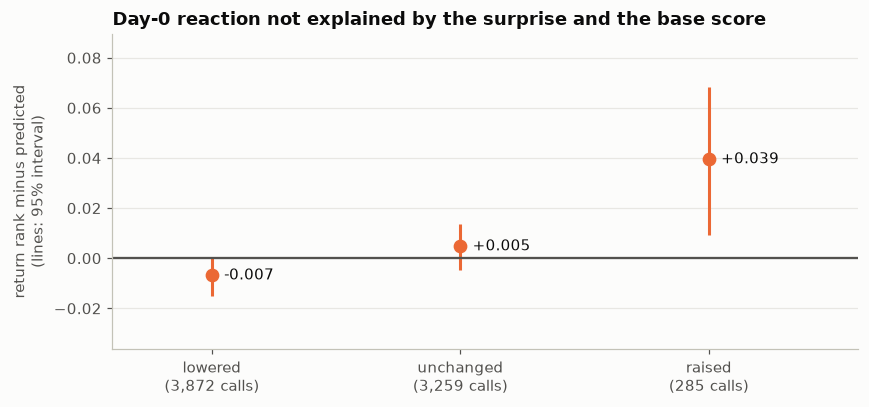

In [6]:
if HAVE_VARIANT:
    moved = m.llm_tone - m.llm_base
    m['moved'] = np.select([moved < 0, moved > 0], ['lowered', 'raised'], 'unchanged')
    m['unexplained'] = smf.ols('r_abn_pct ~ sue_pct_sample + llm_base', data=m).fit().resid
    TONE_WORDS = r'tone|cautio|confiden|hedg|optimis|upbeat|defensive'
    CHANGE_WORDS = (r'earlier|previous|prior (?:call|quarter)|last quarter|than before|shift'
                    r'|more (?:cautious|confident)|less (?:cautious|confident)|improv\w* tone'
                    r'|tone (?:improv|shift|chang)|change in tone')
    def share(reasons, pattern):
        return reasons.reindex(m.index).fillna('').str.lower().str.contains(pattern).mean()
    print(f"The tone prompt changed the score of {(moved != 0).mean():.0%} of calls "
          f"(raised {(moved > 0).mean():.0%}, lowered {(moved < 0).mean():.0%}); mean change {moved.mean():+.3f}; "
          f"correlation with the base score {np.corrcoef(m.llm_base, m.llm_tone)[0, 1]:.3f}.")
    print(f"The model's reasons mention tone in {share(tone_reasons, TONE_WORDS):.0%} of calls with the tone prompt "
          f"against {share(base_reasons, TONE_WORDS):.0%} with the base prompt, and compare with earlier calls in "
          f"{share(tone_reasons, CHANGE_WORDS):.0%} (base: {share(base_reasons, CHANGE_WORDS):.0%}).")

    GROUPS = ['lowered', 'unchanged', 'raised']
    def mean_ci(x):
        # mean with a company bootstrap interval
        pos = np.flatnonzero(m.index.isin(x.index))
        b = [m.unexplained.to_numpy()[i].mean() for i in company_resamples(pos, n=1000)]
        return x.mean(), *np.percentile(b, [2.5, 97.5])
    by = pd.DataFrame([{'group': k, 'calls': int(m.moved.eq(k).sum()),
                        **dict(zip(['mean', 'lo', 'hi'], mean_ci(m.unexplained[m.moved.eq(k)])))} for k in GROUPS]
                      ).set_index('group')
    display(by.assign(share=(by.calls / by.calls.sum()).map('{:.0%}'.format)).round(4))

    fig, ax = plt.subplots(figsize=(8, 3.8))
    p3 = np.arange(len(GROUPS))
    ax.errorbar(p3, by['mean'], yerr=[by['mean'] - by.lo, by.hi - by['mean']], fmt='o', color=ORANGE, ms=8,
                elinewidth=2, capsize=0)
    for i, (k, r) in enumerate(by.iterrows()):
        ax.annotate(f"{r['mean']:+.3f}", (i, r['mean']), xytext=(8, 0), textcoords='offset points', va='center',
                    color=INK)
    ax.axhline(0, color=INK2, lw=1.5)
    ax.set_xticks(p3, [f'{k}\n({by.calls[k]:,} calls)' for k in GROUPS])
    ax.set_xlim(-0.4, len(GROUPS) - 0.4)
    ax.margins(y=0.25)
    ax.set_title('Day-0 reaction not explained by the surprise and the base score')
    ax.set_ylabel('return rank minus predicted\n(lines: 95% interval)')
    ax.grid(axis='x', visible=False)
    fig.tight_layout()
    plt.show()

## 5. Answer

Computed from the numbers above. "Clear" means the 95% interval of the change against the base prompt excludes
zero, or, for the sharper question, a p-value below 0.05.

In [7]:
def verdict(est, lo, hi, what):
    if lo > 0:
        return f'{what} Yes, {est * 100:+.2f} pp (95% interval {lo * 100:+.2f} to {hi * 100:+.2f} pp).'
    if hi < 0:
        return f'{what} No, it is worse: {est * 100:+.2f} pp (95% interval {lo * 100:+.2f} to {hi * 100:+.2f} pp).'
    return (f'{what} No clear effect: {est * 100:+.2f} pp, inside the noise (95% interval {lo * 100:+.2f} to '
            f'{hi * 100:+.2f} pp).')

if not HAVE_VARIANT:
    print(f'Not scored yet: {n_scored:,} of {n_elig:,} calls.')
else:
    print(verdict(est[2] - est[1], *ci(d_alone), '1. Does the tone prompt raise the R² of the LLM score?'))
    print(verdict(est[4] - est[3], *ci(d_both), '2. Does it raise the R² together with the surprise?'))
    print(f"3. Does the tone score add information beyond the base score and the surprise? "
          f"{'Yes' if p < 0.05 else 'No clear evidence'} (p = {p:.3f}).")
    print(f"   Calls whose score the tone prompt raised: {by.loc['raised', 'mean']:+.3f} unexplained rank; "
          f"lowered: {by.loc['lowered', 'mean']:+.3f} (if the tone helps: above and below 0).")

1. Does the tone prompt raise the R² of the LLM score? No, it is worse: -0.91 pp (95% interval -1.44 to -0.37 pp).
2. Does it raise the R² together with the surprise? No clear effect: -0.41 pp, inside the noise (95% interval -0.83 to +0.02 pp).
3. Does the tone score add information beyond the base score and the surprise? Yes (p = 0.009).
   Calls whose score the tone prompt raised: +0.039 unexplained rank; lowered: -0.007 (if the tone helps: above and below 0).


## 6. What it means

- **An improving tone is rare, and it is good news.** When the model saw management sound more confident than
  before, it raised the score, and those stocks did better than expected on day 0. That happened in only 4% of
  calls.
- **"More cautious" is what the model saw most of the time,** and those calls did only slightly worse than
  predicted (-0.7 points, an interval that includes zero). So most of the score changes were noise, which is why
  the ranking got worse (the correlation with the base score fell to 0.91).
- **This call's tone is already in the base prompt.** Every summary has its own TONE AND CAUTION section, and the
  base prompt already tells the model that management's tone matters. The history adds little on top of that.
- **Statistically real is not the same as useful.** p = 0.009 says the tone score isn't pure noise, but +0.08 pp
  of R² on top of 12.69% is far too small to matter in a backtest.

**If tone change is worth another try**
- Ask the model for a **separate rating** of the tone change (more confident / about the same / more cautious),
  instead of folding it into the 0-1 score, and use it as its own variable next to the base score.
- Tell it that cautious quotes are normal in every call and to react only to a clear change.
- Test it on **calls not used here** (for example 2024, or 2026 once CRSP covers it): this run already used the
  2025 calls, so a prompt tuned on these results would look better here than it really is.

**Limits**
- **One year of data.** Q2 calls see only 1 earlier call, and quarter and history length move together, so the
  effect of more history can't be separated from the quarter.
- **Tone from summaries, not transcripts.** The tone notes are about 30 words per call, the LLM's own pick of
  quotes. Tone measured on the full transcripts might do better.
- **The model's reasons** mention tone in every call, but compare with the earlier calls in only 25% of them, so
  it often treated the history as background rather than comparing.
- **One prompt, run once.** The prompt was written before the run and not changed after, so this test is fair. It
  is one of several prompt ideas tried (with `recurring_focus`, `reporting_date` and `insider_trading`).